### Maximum Mean Distance

Use the exact same known-answer tests carried out in the c2st experiments. 

Including the same mean differences:
* mean difference = 0.1
* mean difference = 0.3
* mean difference = 0.5
* mean difference = 1.0

The first function must only measure similarity. 

* Two very close points -> similarity close to 1
* Two distant points -> similarity closer to 0

For reference:
- $k(0, 0)$ should be close to 1.
- $k(0, 0.1) > k(0, 5)$
- $k(x, y) == k(y, x)$

MMD will compare the following similarities:
- similarity inside P
- similarity inside Q
- similarity between P and Q

Verification:

- If $P$ and $Q$ are similar $\rightarrow$ within-sample similarity $\approx$ between-sample similarity
        
- If $MMD^2$ $\approx$ 0 (or negative values close to 0 - do not force negative values to zero) then:  $P$ and $Q$ different.

- within and between similarities stop balancing $\rightarrow$ larger $MMD^2$


Permutation test functionality - to see: What $MMD^2$ would look like if $H_0$ were true?

1. Calculate the real $MMD^2$ between P and Q.

2. Mix P and Q together.

3. Randomly reassign observations into two groups.

4. Calculate $MMD^2$ again.

5. Repeat many times.

6. See how unusual the real $MMD^2$ is compared with those random $MMD^2$ values.

#### Implement RBF kernel

In [15]:
import numpy as np
import pandas as pd

In [2]:
def rbf_kernel(X, Y, sigma=1.0):
    """
    Gaussian / RBF kernel.

    Parameters
    ----------
    X : array-like
        First set of observations.
    Y : array-like
        Second set of observations.
    sigma : float
        Kernel bandwidth. Controls how quickly similarity decreases
        as two points move farther apart.

    Returns
    -------
    K : numpy.ndarray
        Kernel matrix containing the similarity between every point
        in X and every point in Y.
    """

    X = np.asarray(X).reshape(-1, 1)
    Y = np.asarray(Y).reshape(-1, 1)

    squared_distances = (X - Y.T) ** 2

    K = np.exp(
        -squared_distances / (2 * sigma**2)
    )

    return K

Checking the correct functionality of the kernel

In [3]:
print("Same point:")
print(rbf_kernel([0], [0], sigma=1.0))

print("\nClose points:")
print(rbf_kernel([0], [0.1], sigma=1.0))

print("\nFar points:")
print(rbf_kernel([0], [5], sigma=1.0))

Same point:
[[1.]]

Close points:
[[0.99501248]]

Far points:
[[3.72665317e-06]]


In [4]:
a = rbf_kernel([0.5], [2.0], sigma=1.0)
b = rbf_kernel([2.0], [0.5], sigma=1.0)

print(a)
print(b)
print(np.allclose(a, b))

[[0.32465247]]
[[0.32465247]]
True


#### Implement unbiased quadratic $MMD^2$

In [5]:
def mmd2_unbiased(P, Q, sigma=1.0):
    """
    Unbiased quadratic estimator of MMD^2 using an RBF kernel.

    Parameters
    ----------
    P : array-like
        Sample from the first distribution.
    Q : array-like
        Sample from the second distribution.
    sigma : float
        RBF kernel bandwidth.

    Returns
    -------
    mmd2 : float
        Unbiased estimate of MMD^2.
    """

    P = np.asarray(P).reshape(-1, 1)
    Q = np.asarray(Q).reshape(-1, 1)

    m = len(P)
    n = len(Q)

    if m < 2 or n < 2:
        raise ValueError("P and Q must each contain at least 2 observations.")

    if sigma <= 0:
        raise ValueError("sigma must be greater than 0.")

    # Kernel similarities within P, within Q, and between P and Q
    K_PP = rbf_kernel(P, P, sigma=sigma)
    K_QQ = rbf_kernel(Q, Q, sigma=sigma)
    K_PQ = rbf_kernel(P, Q, sigma=sigma)

    # Remove self-similarities from P and Q
    np.fill_diagonal(K_PP, 0)
    np.fill_diagonal(K_QQ, 0)

    # Average similarity within P
    term_P = K_PP.sum() / (m * (m - 1))

    # Average similarity within Q
    term_Q = K_QQ.sum() / (n * (n - 1))

    # Average similarity between P and Q
    term_PQ = K_PQ.sum() / (m * n)

    # Unbiased estimate of MMD^2
    mmd2 = term_P + term_Q - 2 * term_PQ

    return mmd2

In [6]:
# sanity check
rng = np.random.default_rng(42)

n = 1000

P = rng.normal(0, 1, n)
Q_same = rng.normal(0, 1, n)
Q_different = rng.normal(3, 1, n)

mmd_same = mmd2_unbiased(P, Q_same, sigma=1.0)
mmd_different = mmd2_unbiased(P, Q_different, sigma=1.0)

print("Same distributions:")
print(mmd_same)

print("\nDifferent distributions:")
print(mmd_different)

Same distributions:
-0.00018848805089710652

Different distributions:
0.9121948562979665


#### Permutation test

In [7]:
def mmd_permutation_test(
    P,
    Q,
    sigma=1.0,
    n_permutations=200,
    alpha=0.05,
    seed=42
):
    """
    Permutation test for the unbiased MMD^2 statistic.

    Parameters
    ----------
    P : array-like
        Sample from the first distribution.
    Q : array-like
        Sample from the second distribution.
    sigma : float
        RBF kernel bandwidth.
    n_permutations : int
        Number of random permutations used to approximate
        the null distribution.
    alpha : float
        Significance level.
    seed : int
        Random seed for reproducibility.

    Returns
    -------
    result : dict
        Observed MMD^2, p-value, decision, and permutation statistics.
    """

    P = np.asarray(P).reshape(-1)
    Q = np.asarray(Q).reshape(-1)

    rng = np.random.default_rng(seed)

    # 1. Calculate the real MMD^2
    observed_mmd2 = mmd2_unbiased(
        P,
        Q,
        sigma=sigma
    )

    # 2. Combine both samples
    combined = np.concatenate([P, Q])

    m = len(P)

    # Store the MMD^2 obtained under random permutations
    permutation_mmd2 = np.empty(n_permutations)

    # 3. Randomly shuffle the origin labels
    for i in range(n_permutations):

        permutation = rng.permutation(len(combined))

        P_perm = combined[permutation[:m]]
        Q_perm = combined[permutation[m:]]

        # 4. Calculate MMD^2 after the random reassignment
        permutation_mmd2[i] = mmd2_unbiased(
            P_perm,
            Q_perm,
            sigma=sigma
        )

    # 5. Calculate the permutation p-value
    p_value = (
        1 + np.sum(permutation_mmd2 >= observed_mmd2)
    ) / (n_permutations + 1)

    # 6. Statistical decision
    reject_H0 = p_value < alpha

    return {
        "mmd2": observed_mmd2,
        "p_value": p_value,
        "reject_H0": reject_H0,
        "alpha": alpha,
        "sigma": sigma,
        "n_permutations": n_permutations,
        "seed": seed,
        "permutation_mmd2": permutation_mmd2
    }

`mmd_permutation_test()`: calculates MMD from the original Gaussian distributions, later performs the 200 permutations to determine if the MMD is large enough to reject $H_0$. 

In [8]:
# H0 test
rng = np.random.default_rng(42)

n = 1000

P = rng.normal(0, 1, n)
Q = rng.normal(0, 1, n)

result_same = mmd_permutation_test(
    P,
    Q,
    sigma=1.0,
    n_permutations=200,
    alpha=0.05,
    seed=42
)

print("MMD^2:", result_same["mmd2"])
print("p-value:", result_same["p_value"])
print("Reject H0:", result_same["reject_H0"])

MMD^2: -0.00018848805089710652
p-value: 0.5074626865671642
Reject H0: False


Negative value close to 0 indicates similarity, p val > 0.05, doesn't reject H0 - passed sanity check

In [9]:
# H1 test 

rng = np.random.default_rng(42)

n = 1000

P = rng.normal(0, 1, n)
Q = rng.normal(3, 1, n)

result_different = mmd_permutation_test(
    P,
    Q,
    sigma=1.0,
    n_permutations=200,
    alpha=0.05,
    seed=42
)

print("MMD^2:", result_different["mmd2"])
print("p-value:", result_different["p_value"])
print("Reject H0:", result_different["reject_H0"])

MMD^2: 0.8823201729309227
p-value: 0.004975124378109453
Reject H0: True


larger MMD value, p val < 0.05 , rejects H0 - passed

#### Same distribution test 

In [10]:
# data generation
rng = np.random.default_rng(42)

n = 1000

P = rng.normal(0, 1, n)
Q = rng.normal(0, 1, n)

In [11]:
# same distribution
result_same = mmd_permutation_test(
    P,
    Q,
    sigma=1.0,
    n_permutations=200,
    alpha=0.05,
    seed=42
)

print("MMD^2:", result_same["mmd2"])
print("p-value:", result_same["p_value"])
print("Reject H0:", result_same["reject_H0"])

MMD^2: -0.00018848805089710652
p-value: 0.5074626865671642
Reject H0: False


#### Different distribution

In [12]:
rng = np.random.default_rng(42)

n = 1000

P = rng.normal(0, 1, n)
Q = rng.normal(3, 1, n)

result_different = mmd_permutation_test(
    P,
    Q,
    sigma=1.0,
    n_permutations=200,
    alpha=0.05,
    seed=42
)

print("MMD^2:", result_different["mmd2"])
print("p-value:", result_different["p_value"])
print("Reject H0:", result_different["reject_H0"])

MMD^2: 0.8823201729309227
p-value: 0.004975124378109453
Reject H0: True


#### $MMD$ Known-Answer Sanity Check

The baseline $MMD$ configuration used an RBF kernel with sigma = 1.0, the unbiased quadratic $MMD^2$ estimator, alpha = 0.05, and a permutation test.

For two samples drawn from the same distribution, $MMD^2$ was close to zero and the test did not reject $H_0$.

For clearly different distributions, $MMD^2$ was larger and the test rejected $H_0$.

Therefore, the initial $MMD$ implementation passed the basic known-answer sanity check.

#### Known-answer test with smaller mean differences

Only 20 repetitions to verify the experiment works correctly.

In [13]:
# function to repeat MMD 
def repeat_mmd(
    mu_P,
    mu_Q,
    n=300,
    repetitions=20,
    sigma=1.0,
    n_permutations=200,
    alpha=0.05
):
    """
    Repeat the MMD permutation test on Gaussian distributions.

    P ~ N(mu_P, 1)
    Q ~ N(mu_Q, 1)
    """

    results = []

    for seed in range(repetitions):

        # Generate a new pair of samples for each repetition
        rng = np.random.default_rng(seed)

        P = rng.normal(
            loc=mu_P,
            scale=1,
            size=n
        )

        Q = rng.normal(
            loc=mu_Q,
            scale=1,
            size=n
        )

        # Use a separate seed for the permutation procedure
        result = mmd_permutation_test(
            P,
            Q,
            sigma=sigma,
            n_permutations=n_permutations,
            alpha=alpha,
            seed=10000 + seed
        )

        results.append({
            "mu_P": mu_P,
            "mu_Q": mu_Q,
            "mean_difference": abs(mu_Q - mu_P),
            "n": n,
            "sigma": sigma,
            "mmd2": result["mmd2"],
            "p_value": result["p_value"],
            "reject_H0": result["reject_H0"],
            "seed": seed
        })

    return results

In [16]:
# test more mean differences
mean_differences = [0, 0.1, 0.3, 0.5, 1.0]

summary = []
all_results = []

for delta in mean_differences:

    results = repeat_mmd(
        mu_P=0,
        mu_Q=delta,
        n=300,
        repetitions=20,
        sigma=1.0,
        n_permutations=200,
        alpha=0.05
    )

    # Save individual runs
    all_results.extend(results)

    # Percentage of experiments that rejected H0
    rejection_rate = np.mean([
        result["reject_H0"]
        for result in results
    ])

    # Interpretation depends on whether H0 is true
    if delta == 0:
        interpretation = "Type I error"
    else:
        interpretation = "Power"

    summary.append({
        "comparison": f"N(0,1) vs N({delta},1)",
        "mean_difference": delta,
        "rejection_rate": rejection_rate,
        "interpretation": interpretation
    })

summary_df = pd.DataFrame(summary)

print(summary_df)

           comparison  mean_difference  rejection_rate interpretation
0    N(0,1) vs N(0,1)              0.0            0.10   Type I error
1  N(0,1) vs N(0.1,1)              0.1            0.20          Power
2  N(0,1) vs N(0.3,1)              0.3            0.85          Power
3  N(0,1) vs N(0.5,1)              0.5            1.00          Power
4  N(0,1) vs N(1.0,1)              1.0            1.00          Power


The 0.10 type 1 error means that 2/20 runs under $H_0$ rejected $H_0$ incorrectly: 2 false positives. It is necessary to perform more repetitions to evaluate calibration. 

In [17]:
all_results_df = pd.DataFrame(all_results)

all_results_df.to_csv(
    "../results/mmd_mean_shift_runs.csv",
    index=False
)

summary_df.to_csv(
    "../results/mmd_mean_shift_summary.csv",
    index=False
)

### First MMD Sensitivity Results

For a mean difference of $0.1$, MMD rejected $H_0$ in $20\%$ of the repetitions.
Power increased to $85\%$ for a mean difference of $0.3$, and $MMD$ rejected $H_0$ in all $20$ repetitions for mean differences of $0.5$ and $1.0$.

Under $H_0$, the estimated Type I error was $0.10$, corresponding to $2$ false rejections out of $20$ repetitions. Because only $20$ repetitions were performed, this estimate is too coarse to conclude that the test is miscalibrated.

The test's sensitivity is leaning towards the right direction: larger separation between $P$ and $Q$ leads to higher MMD power. This experiment mantains a reasonable type 1 error, and it is clear how the test's power increases as the mean difference becomes larger. Therefore, results suggest that the MMD implementation responds in the expected direction as the separation between the distributions increases. More repetitions are needed before estimating Type I error and power more precisely.



#### 1000 reps

In [18]:
mean_differences = [0, 0.1, 0.3, 0.5, 1.0]

repetitions = 1000
n = 300
sigma = 1.0
n_permutations = 200
alpha = 0.05

summary_1000 = []
all_results_1000 = []

for delta in mean_differences:

    print(f"Running: N(0,1) vs N({delta},1)")

    results = repeat_mmd(
        mu_P=0,
        mu_Q=delta,
        n=n,
        repetitions=repetitions,
        sigma=sigma,
        n_permutations=n_permutations,
        alpha=alpha
    )

    all_results_1000.extend(results)

    rejection_rate = np.mean([
        result["reject_H0"]
        for result in results
    ])

    if delta == 0:
        interpretation = "Type I error"
    else:
        interpretation = "Power"

    summary_1000.append({
        "comparison": f"N(0,1) vs N({delta},1)",
        "mean_difference": delta,
        "rejection_rate": rejection_rate,
        "interpretation": interpretation
    })

summary_1000_df = pd.DataFrame(summary_1000)

print("\nFinal summary:")
print(summary_1000_df)

Running: N(0,1) vs N(0,1)
Running: N(0,1) vs N(0.1,1)
Running: N(0,1) vs N(0.3,1)
Running: N(0,1) vs N(0.5,1)
Running: N(0,1) vs N(1.0,1)

Final summary:
           comparison  mean_difference  rejection_rate interpretation
0    N(0,1) vs N(0,1)              0.0           0.053   Type I error
1  N(0,1) vs N(0.1,1)              0.1           0.190          Power
2  N(0,1) vs N(0.3,1)              0.3           0.893          Power
3  N(0,1) vs N(0.5,1)              0.5           1.000          Power
4  N(0,1) vs N(1.0,1)              1.0           1.000          Power


In [19]:
all_results_1000_df = pd.DataFrame(all_results_1000)

all_results_1000_df.to_csv(
    "../results/mmd_mean_shift_1000_runs.csv",
    index=False
)

summary_1000_df.to_csv(
    "../results/mmd_mean_shift_1000_summary.csv",
    index=False
)

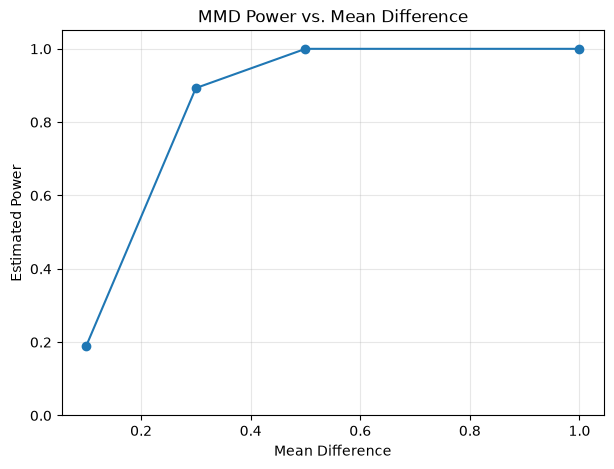

In [23]:
import matplotlib.pyplot as plt

# Keep only the alternative-hypothesis cases
power_df = summary_1000_df[
    summary_1000_df["mean_difference"] > 0
]

plt.figure(figsize=(7, 5))

plt.plot(
    power_df["mean_difference"],
    power_df["rejection_rate"],
    marker="o"
)

plt.xlabel("Mean Difference")
plt.ylabel("Estimated Power")
plt.title("MMD Power vs. Mean Difference")

plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)

plt.show()

#### 1000 repetitions preliminary results

The baseline MMD configuration shows the expected sensitivity trend: as the difference between the means of P and Q increases, the estimated statistical power also increases.

I initially considered 1,000 repetitions to match the C2ST experiment. However, because MMD requires an internal permutation test and is more computationally expensive, exploratory Week 3 experiments can use fewer repetitions to validate implementation and identify sensitivity patterns. The final metric comparison will use a matched experimental design so that differences between metrics are not confounded by different sample sizes.




**How much does MMD performance change when only the kernel bandwidth changes?**